
[CA1] pooled rows: 230418
   state window       n
0  AWAKE    30s  103565
1  AWAKE    60s   22446
2   NREM    30s   83207
3   NREM    60s   18289
4    REM    30s    2622
5    REM    60s     289
Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\S2_C_CA1_snr_box_30s_vs_60s.svg


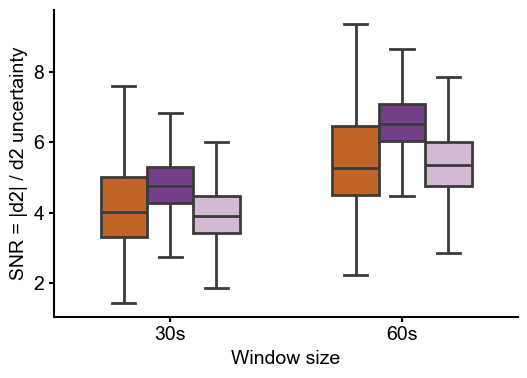


🔹 Running two-way ANOVA on 230418 SNR samples ...

📊 ANOVA results (state × window):
                         sum_sq        df           F  PR(>F)
C(state)             25458.0199       2.0  10941.3203     0.0
C(window)            83711.5025       1.0  71954.8781     0.0
C(state):C(window)    1384.5528       2.0    595.0516     0.0
Residual            268058.7503  230412.0         NaN     NaN

🔹 Paired state comparisons per session (animal × day):

Window = 30s
  AWAKE vs NREM: n=18, p=3.81e-05
  NREM vs REM:  n=16, p=3.05e-05

Window = 60s
  AWAKE vs NREM: n=11, p=0.000977
  NREM vs REM:  n=9, p=0.00781

🔹 Paired comparison of window length (30s vs 60s, across all states):
  30s vs 60s: n=11, p=0.000977

📊 Multiple comparison correction (Holm-Bonferroni):
  AWAKE vs NREM        | n=18 | p=3.815e-05 | p_adj=1.526e-04 | ***
  NREM vs REM          | n=16 | p=3.052e-05 | p_adj=1.526e-04 | ***
  AWAKE vs NREM        | n=11 | p=9.766e-04 | p_adj=2.930e-03 | **
  NREM vs REM          | n= 9 

In [2]:
import os, re, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match (works if those faces exist on your system)
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# ------------------ Helpers ------------------
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(mat_path, squeeze_me=True, struct_as_record=False, simplify_cells=True)
    except TypeError:
        return loadmat(mat_path, squeeze_me=True, struct_as_record=False)
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)

def _to_1d_array(x):
    if x is None:
        return np.array([], dtype=float)
    arr = np.asarray(x, dtype=object)
    if arr.ndim == 0:
        return np.atleast_1d(arr).astype(float, copy=False)
    try:
        return np.asarray(arr).ravel().astype(float, copy=False)
    except (ValueError, TypeError):
        return np.array([float(v) for v in np.ravel(arr)], dtype=float)

def _to_state_str(s):
    try:
        if isinstance(s, (bytes, bytearray)):
            return s.decode('utf-8', 'ignore')
        if isinstance(s, str):
            return s
        arr = np.asarray(s)
        if arr.ndim == 0:
            return str(arr.item())
        return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
    except Exception:
        return str(s)

# === Additions to your previous script ===
# Reuse: _load_mat_any, _to_1d_array, _to_state_str, _infer_animal_day_from_path

def _extract_d2_and_err_by_state_from_mat(mat_path, region=None, animal=None, day=None):
    """
    Extract both d2 and d2_err pooled by state.
    Returns DataFrame with columns: state, d2, d2_err, region, animal, day
    (Rows are per-window; missing d2_err become NaN.)
    """
    mat = _load_mat_any(mat_path)
    results = mat.get('results', None)
    if results is None:
        return pd.DataFrame(columns=["state","d2","d2_err","region","animal","day"])

    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    rows = []
    for it in iter_results:
        if hasattr(it, 'get'):
            st = _to_state_str(it.get('state', 'UNKNOWN'))
            d2_raw = it.get('d2', [])
            d2err_raw = it.get('d2_err', [])
        elif isinstance(it, dict) or hasattr(it, '__getitem__'):
            st = _to_state_str(it.get('state', it['state'] if 'state' in it else 'UNKNOWN'))
            d2_raw = it.get('d2', it['d2'] if 'd2' in it else [])
            d2err_raw = it.get('d2_err', it['d2_err'] if 'd2_err' in it else [])
        else:
            st, d2_raw, d2err_raw = 'UNKNOWN', [], []

        d2_vals = _to_1d_array(d2_raw)
        d2_vals = d2_vals[np.isfinite(d2_vals)]
        if d2_vals.size == 0:
            continue

        d2_err = _to_1d_array(d2err_raw)
        d2_err = d2_err[np.isfinite(d2_err)] if d2_err.size else np.array([], float)

        st_up = st.upper()
        if st_up == "WAKE":
            st_up = "AWAKE"
        if st_up not in ("NREM", "AWAKE", "REM"):
            continue

        # Align lengths if both present; otherwise, pad err with NaN
        n = d2_vals.size
        if d2_err.size >= n:
            d2_err = d2_err[:n]
        elif d2_err.size == 0:
            d2_err = np.full(n, np.nan)
        else:
            # rare mismatch; trim both to min
            m = min(n, d2_err.size)
            d2_vals = d2_vals[:m]
            d2_err = d2_err[:m]

        rows.append(pd.DataFrame({
            "state": st_up,
            "d2": d2_vals,
            "d2_err": d2_err,
            "region": region if region else "",
            "animal": animal if animal else "",
            "day": day if day is not None else ""
        }))

    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame(
        columns=["state","d2","d2_err","region","animal","day"]
    )

def _infer_animal_day_from_path(basepath):
    base = os.path.basename(basepath.rstrip("\\/"))
    # try ...\PPP20\day4 or ...\NN2\day24 etc.
    animal = os.path.basename(os.path.dirname(basepath))
    mday = re.search(r"day(\d+)", base, flags=re.I)
    day = int(mday.group(1)) if mday else None
    return animal, day
def load_d2_and_err_30s_60s_from_session(basepath, region):
    """
    For a single basepath+region, load newest 30s and 60s files and return
    pooled d2 and d2_err with a 'window' column ∈ {'30s','60s'}.
    """
    region = region.upper()
    search_dir = Path(basepath) / "complex_system"
    if not search_dir.exists():
        return pd.DataFrame(columns=["state","d2","d2_err","window","region","animal","day"])

    pats = {
        "30s": f"*_{region}_D2_time_resolved_error_bar.mat",
        "60s": f"*_{region}_D2_time_resolved_error_bar_60sec.mat",
    }
    animal, day = _infer_animal_day_from_path(basepath)
    out = []
    for win_label, pat in pats.items():
        files = glob.glob(str(search_dir / pat))
        if not files:
            continue
        mat_path = max(files, key=os.path.getmtime)
        df = _extract_d2_and_err_by_state_from_mat(mat_path, region=region, animal=animal, day=day)
        if df.empty:
            continue
        df["window"] = win_label
        out.append(df)

    return pd.concat(out, ignore_index=True) if out else pd.DataFrame(
        columns=["state","d2","d2_err","window","region","animal","day"]
    )

def plot_box_by_window(df, ycol, region, title=None, save_path=None, zscore_per_session=False):
    """
    Generic box plot for ycol ∈ {'d2','d2_err'} comparing 30s vs 60s per state.
    If zscore_per_session=True and ycol=='d2', d2 is z-scored within (animal, day, window, state).
    """
    if df.empty:
        print(f"[{region}] No data to plot for {ycol}.")
        return

    order = ["NREM", "AWAKE", "REM"]
    df = df[df["state"].isin(order)].copy()
    df["state"] = pd.Categorical(df["state"], categories=order, ordered=True)

    data = df.copy()
    if zscore_per_session and ycol == "d2":
        # z-score d2 within session-window-state to reduce across-session scale differences
        def _zs(g):
            v = g[ycol].values
            m, s = np.nanmean(v), np.nanstd(v, ddof=0)
            if not np.isfinite(s) or s == 0:
                return pd.Series(np.zeros_like(v), index=g.index)
            return pd.Series((v - m) / s, index=g.index)
        data[ycol + "_z"] = data.groupby(["animal","day","window","state"], observed=True).apply(_zs).reset_index(level=[0,1,2,3], drop=True)
        ycol_plot = ycol + "_z"
        ylab = f"{ycol} (z-scored per session/window/state)"
    else:
        ycol_plot = ycol
        ylab = ycol

    plt.figure(figsize=(7,4))
    ax = sns.boxplot(data=data, x="state", y=ycol_plot, hue="window",
                     showcaps=True, width=0.7, boxprops=dict(alpha=0.8))
    sns.despine()
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlabel("State")
    ax.set_ylabel(ylab if ycol != "d2_err" else "d² uncertainty (d2_err)")
    ax.set_title(title or f"{region}: {ycol} (30s vs 60s)")
    ax.legend(title="Window", frameon=False)
    plt.tight_layout()
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300)
        print(f"Saved: {save_path}")
    plt.show()
paths = [
    r"W:\data\PPP\PPP20\day4",
    r"W:\data\PPP\PPP20\day5",
    r"W:\data\PPP\PPP20\day7",
    r"W:\data\PPP\PPP20\day8",
    r"W:\data\PPP\PPP20\day9",
    r"W:\data\PPP\PPP21\day4",
    r"W:\data\PPP\PPP21\day5",
    r"W:\data\PPP\PPP21\day7",
    r"W:\data\PPP\PPP21\day8",
    r"W:\data\PPP\PPP8\day8",
    r"W:\data\PPP\PPP8\day14",
    r"W:\data\PPP\PPP4\day11",
    r"W:\data\PPP\PPP7\day7",
    r"W:\data\PPP\PPP7\day10",
    r"W:\data\PPP\PPP7\day12",
    r"W:\data\PPP\PPP7\day14",
    r"W:\data\PPP\PPP23\day7",
    r"W:\data\PPP\PPP23\day8",
]
# === Main pooling across all sessions (update your earlier loop) ===
regions = ["CA1"]
pooled_all = {reg: [] for reg in regions}
missing = []

for basepath in paths:
    for reg in regions:
        try:
            df_session = load_d2_and_err_30s_60s_from_session(basepath, reg)
            if not df_session.empty:
                pooled_all[reg].append(df_session)
            else:
                missing.append((basepath, reg))
        except Exception as e:
            print(f"⚠️ {reg} @ {basepath}: {e}")
            missing.append((basepath, reg))

save_root = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp"
for reg in regions:
    if not pooled_all[reg]:
        print(f"\n[{reg}] No data found across all sessions.")
        continue

    df_reg = pd.concat(pooled_all[reg], ignore_index=True)
    # Quick counts
    print(f"\n[{reg}] pooled rows: {len(df_reg)}")
    print(df_reg.groupby(["state","window"]).size().rename("n").reset_index())

    # # --- Plot d2_err (uncertainty) as before ---
    # plot_box_by_window(
    #     df_reg, ycol="d2_err", region=reg,
    #     title=f"{reg}: d² uncertainty (30s vs 60s)",
    #     save_path=os.path.join(save_root, f"{reg}_d2err_box_30s_vs_60s.svg")
    # )

    # # --- Plot d2 itself (raw) ---
    # plot_box_by_window(
    #     df_reg, ycol="d2", region=reg,
    #     title=f"{reg}: d² (30s vs 60s, pooled)",
    #     save_path=os.path.join(save_root, f"{reg}_d2_box_30s_vs_60s_raw.svg"),
    #     zscore_per_session=False   # set True if you want per-session normalization
    # )
# ---------- SNR helpers ----------
def add_snr(df, eps=1e-12):
    """Add SNR = |d2| / (d2_err + eps). Leaves existing columns untouched."""
    d = df.copy()
    if "d2_err" not in d.columns or "d2" not in d.columns:
        raise KeyError("DataFrame must contain 'd2' and 'd2_err' columns to compute SNR.")
    d["snr"] = np.abs(d["d2"]) / (np.asarray(d["d2_err"]) + eps)
    # cleanup non-finite
    d.loc[~np.isfinite(d["snr"]), "snr"] = np.nan
    return d

def plot_snr_by_window(df, region, title=None, save_path=None, log10=False):
    """
    Box plot of SNR comparing sleep states (NREM/AWAKE/REM) within each window (30s vs 60s).
    x-axis = window (30s, 60s), hue = state.
    """
    if df.empty:
        print(f"[{region}] No data to plot for SNR.")
        return

    order_states = ["NREM", "AWAKE", "REM"]
    order_windows = ["30s", "60s"]

    d = df[df["state"].isin(order_states) & df["window"].isin(order_windows)].copy()
    if d.empty:
        print(f"[{region}] No valid rows for SNR plotting.")
        return
    d["state"] = pd.Categorical(d["state"], categories=order_states, ordered=True)
    d["window"] = pd.Categorical(d["window"], categories=order_windows, ordered=True)

    ycol = "snr"
    ylabel = "SNR = |d2| / d2 uncertainty"
    if log10:
        d[ycol] = np.clip(d[ycol].values, 1e-12, np.inf)
        d["log10_snr"] = np.log10(d[ycol].values)
        ycol = "log10_snr"
        ylabel = "log10 SNR"

    plt.figure(figsize=(5.5, 4))

    palette = {
    "AWAKE": "#d95f0e",  # green
    "NREM":  "#7b3294",  # blue
    "REM":  "#d7b5d8",  # red
     }
    order_states = ["AWAKE","NREM",  "REM"]
    ax = sns.boxplot(
        data=d,
        x="window",          # <-- now window on x-axis
        y=ycol,
        hue="state",         # <-- states as hue groups
        showcaps=True,
        boxprops=dict(alpha=1),
        hue_order=order_states,
        palette=palette,
        showfliers=False,
        width=0.6,
        linewidth=2
    )

    sns.despine()
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Window size")
    leg = ax.get_legend()
    if leg is not None:
        leg.remove()   # or: leg.set_visible(False)
    plt.tight_layout()

    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300)
        print(f"Saved: {save_path}")

    plt.show()


def summarize_snr(df):
    """
    Print quick summary stats for SNR per state x window:
    median, IQR, and fraction SNR<1.
    """
    d = df.dropna(subset=["snr"]).copy()
    if d.empty:
        print("No finite SNR to summarize.")
        return
    grp = d.groupby(["state","window"])
    summary = grp["snr"].agg(
        n="size",
        median=np.median,
        q25=lambda x: np.quantile(x, 0.25),
        q75=lambda x: np.quantile(x, 0.75),
        frac_snr_lt1=lambda x: np.mean(np.asarray(x) < 1.0)
    ).reset_index()
    print("\nSNR summary (per state × window):")
    print(summary.to_string(index=False))
    return summary


# --- Compute and plot SNR ---
df_reg_snr = add_snr(df_reg)

# Linear SNR
plot_snr_by_window(
    df_reg_snr, region=reg,
    title=f"{reg}: SNR (30s vs 60s)",
    save_path=os.path.join(save_root, f"S2_C_{reg}_snr_box_30s_vs_60s.svg"),
    log10=False
)

import pingouin as pg   # clean, statsmodels-based ANOVA lib
import statsmodels.api as sm
from statsmodels.formula.api import ols
import pingouin as pg
import statsmodels.api as sm
from statsmodels.formula.api import ols

from scipy.stats import ttest_ind

from scipy.stats import wilcoxon

from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

def run_anova_snr(df):
    """
    Two-way ANOVA on SNR with factors:
        - state (NREM / AWAKE / REM)
        - window (30s / 60s)
    
    PLUS paired comparisons across sessions (animal × day):

      (A) Within each window:
          - AWAKE vs NREM
          - NREM vs REM

      (B) Across windows (pooling all states):
          - 30s vs 60s (per-session mean over states)
          
    WITH multiple comparison correction (Holm-Bonferroni)
    """
    # ---------------------------------------
    # 1. Basic cleanup
    # ---------------------------------------
    d = df.dropna(subset=["snr"]).copy()

    # filters
    d = d[d["state"].isin(["NREM", "AWAKE", "REM"])]
    d = d[d["window"].isin(["30s", "60s"])]

    if d.empty:
        print("No valid SNR data for ANOVA.")
        return None, None

    # Session identity = animal × day
    d["session"] = d["animal"].astype(str) + "_" + d["day"].astype(str)

    print(f"\n🔹 Running two-way ANOVA on {len(d)} SNR samples ...")

    # ---------------------------------------
    # 2. Two-way ANOVA (state × window)
    # ---------------------------------------
    model = ols("snr ~ C(state) * C(window)", data=d).fit()
    table = sm.stats.anova_lm(model, typ=2)

    print("\n📊 ANOVA results (state × window):")
    print(table.round(4))

    # ---------------------------------------
    # 3. Paired state comparisons per window
    # ---------------------------------------
    print("\n🔹 Paired state comparisons per session (animal × day):")

    pairwise_rows = []

    for win in sorted(d["window"].unique()):
        print(f"\nWindow = {win}")

        dw = d[d["window"] == win].copy()

        # Per session × state mean SNR
        pivot = (
            dw.groupby(["session", "state"])["snr"]
              .mean()
              .unstack("state")
        )

        # AWAKE vs NREM
        if {"AWAKE", "NREM"}.issubset(pivot.columns):
            x = pivot["AWAKE"]
            y = pivot["NREM"]
            mask = x.notna() & y.notna()
            if mask.sum() > 1:
                stat, p = wilcoxon(x[mask], y[mask])
                print(f"  AWAKE vs NREM: n={mask.sum()}, p={p:.3g}")
                pairwise_rows.append(
                    {"type": "state",
                     "window": win,
                     "contrast": "AWAKE vs NREM",
                     "p": p,
                     "n": mask.sum()}
                )
            else:
                print("  AWAKE vs NREM: insufficient paired samples.")

        # NREM vs REM
        if {"NREM", "REM"}.issubset(pivot.columns):
            x = pivot["NREM"]
            y = pivot["REM"]
            mask = x.notna() & y.notna()
            if mask.sum() > 1:
                stat, p = wilcoxon(x[mask], y[mask])
                print(f"  NREM vs REM:  n={mask.sum()}, p={p:.3g}")
                pairwise_rows.append(
                    {"type": "state",
                     "window": win,
                     "contrast": "NREM vs REM",
                     "p": p,
                     "n": mask.sum()}
                )
            else:
                print("  NREM vs REM: insufficient paired samples.")

    # ---------------------------------------
    # 4. Paired comparison of window length (30s vs 60s),
    #    pooling across states
    # ---------------------------------------
    print("\n🔹 Paired comparison of window length (30s vs 60s, across all states):")

    # Per session × window mean SNR (averaged over all states)
    pivot_win = (
        d.groupby(["session", "window"])["snr"]
          .mean()
          .unstack("window")
    )

    if {"30s", "60s"}.issubset(pivot_win.columns):
        x = pivot_win["30s"]
        y = pivot_win["60s"]
        mask = x.notna() & y.notna()
        if mask.sum() > 1:
            stat, p = wilcoxon(x[mask], y[mask])
            print(f"  30s vs 60s: n={mask.sum()}, p={p:.3g}")
            pairwise_rows.append(
                {"type": "window",
                 "window": "all_states",
                 "contrast": "30s vs 60s",
                 "p": p,
                 "n": mask.sum()}
            )
        else:
            print("  30s vs 60s: insufficient paired samples.")
    else:
        print("  30s vs 60s: not both windows present.")

    # ---------------------------------------
    # 5. Multiple comparison correction
    # ---------------------------------------
    if pairwise_rows:
        pairwise_df = pd.DataFrame(pairwise_rows)

        # Apply Holm-Bonferroni correction
        reject, p_adj, _, _ = multipletests(
            pairwise_df["p"].values,
            method='holm'
        )

        pairwise_df["p_adj"] = p_adj
        pairwise_df["reject"] = reject

        print("\n📊 Multiple comparison correction (Holm-Bonferroni):")
        print("=" * 80)
        for _, row in pairwise_df.iterrows():
            sig = "***" if row["p_adj"] < 0.001 else "**" if row["p_adj"] < 0.01 else "*" if row["p_adj"] < 0.05 else "n.s."
            print(f"  {row['contrast']:20s} | n={row['n']:2d} | p={row['p']:.3e} | p_adj={row['p_adj']:.3e} | {sig}")
    else:
        pairwise_df = None

    return table, pairwise_df


df_reg_snr = add_snr(df_reg)

anova_table, pairwise_df = run_anova_snr(df_reg_snr)

FigS2C_uncertianty


✅ Used 12 files; skipped 0.
tile
1    11152
2     8641
3     7892
4     8268
5     7956
6     6913
Name: count_by_tile, dtype: int64

✅ Used 12 files; skipped 0.
tile
1    11152
2     8641
3     7892
4     8268
5     7956
6     6913
Name: count_by_tile, dtype: int64

📊 Linear trend on pooled means (Ripple rate quantiles (low → high)):
   R² = 0.942, p = 0.001
   counts per tile:
 tile
1    12
2    12
3    12
4    12
5    12
6    12
Figure saved to D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\S2_C_ripple_rate_by_d2_tile_pooled_std.svg


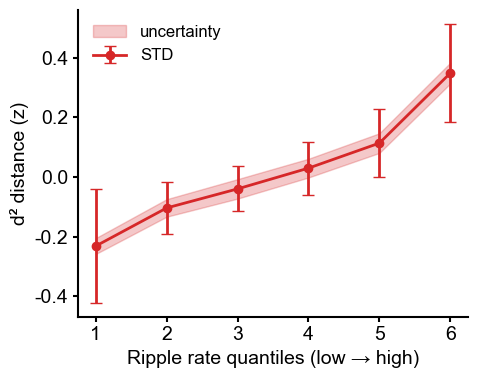

In [1]:
import os, pickle
import numpy as np
import pandas as pd
from scipy.stats import sem, linregress
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path # Added Path
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# Make mathtext look like Arial
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Arial'
mpl.rcParams['mathtext.it'] = 'Arial:italic'
mpl.rcParams['mathtext.bf'] = 'Arial:bold' 

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# ==========================
import numpy as np
import pandas as pd
from pathlib import Path
import pickle

# -------------------------------------------------
# Helper: force sextiles (or k-tiles) 1..k
# -------------------------------------------------
def _force_sextiles(series, k=6):
    """
    Return Int64 tiles 1..k. Try qcut; if it yields <k bins, fall back to
    rank-based qcut that still returns k bins when N>=k. If N<k -> all NA.
    """
    s = pd.to_numeric(series, errors="coerce")
    s = s.replace([np.inf, -np.inf], np.nan)

    # 1) Try ordinary quantile sextiles
    try:
        t = pd.qcut(s, q=k, labels=False, duplicates="drop")
        if pd.Series(t).nunique(dropna=True) == k:
            return t.astype("Int64") + 1
    except Exception:
        pass

    # 2) Fallback: rank-based sextiles (equal-count by rank)
    rk = s.rank(method="first")
    if rk.notna().sum() >= k:
        t = pd.qcut(rk, q=k, labels=False)
        return t.astype("Int64") + 1

    # 3) Not enough rows to form k bins
    return pd.Series(pd.NA, index=s.index, dtype="Int64")


# -------------------------------------------------
# Main loader
# -------------------------------------------------
def load_pool_rate_binned(
    pkl_dir,
    rate_col,                 # "ripple_rate_hz" or "barrage_rate_hz"
    d2_col="d2",              # D2 column name in source file
    d2_err_col="d2_err",      # D2 error column name in source file
    state="NREM",
    n_bins=6,
    min_bins_required=2,      # skip a file if effective bins < min_bins_required
):
    pooled = []
    n_files_used = 0
    n_files_skipped = 0
    
    # Use Path to handle directory
    pkl_dir = Path(pkl_dir)

    for file_path in pkl_dir.glob("*.pkl"):
        try:
            with open(file_path, "rb") as f:
                # Load the entire pickled object
                data_obj = pickle.load(f)

            # Try to find the dataframe, assuming it might be in a dict
            df = None
            if isinstance(data_obj, pd.DataFrame):
                df = data_obj
            elif isinstance(data_obj, dict):
                # Check for common keys
                if "ca1_complete_df" in data_obj:
                    df = data_obj["ca1_complete_df"]
                elif "df" in data_obj:
                    df = data_obj["df"]
                
            if df is None or len(df) == 0:
                print(f"⚠️ Skipped {file_path.name} (no usable DataFrame)")
                n_files_skipped += 1
                continue

            # state filter
            if "state" not in df.columns:
                print(f"⚠️ Skipped {file_path.name} (no 'state' column)")
                n_files_skipped += 1
                continue
                
            df = df[df["state"] == state].copy()
            if df.empty:
                print(f"⚠️ Skipped {file_path.name} (no {state} rows)")
                n_files_skipped += 1
                continue

            # keep only needed cols, drop NaNs
            need = [d2_col, rate_col]
            has_d2err = d2_err_col in df.columns
            if has_d2err:
                need.append(d2_err_col)
            
            if not set(need).issubset(df.columns):
                missing = set(need) - set(df.columns)
                print(f"⚠️ Skipped {file_path.name} (missing {missing})")
                n_files_skipped += 1
                continue
                
            df = df[need].dropna()
            if df.empty:
                print(f"⚠️ Skipped {file_path.name} (NaNs after subset)")
                n_files_skipped += 1
                continue

            # z-normalize D² within this file
            d2_mean = df[d2_col].mean()
            d2_std = df[d2_col].std(ddof=0)  # Use ddof=0 for population std
            
            if d2_std == 0 or np.isnan(d2_std):
                print(f"⚠️ Skipped {file_path.name} (zero/NaN std of d2)")
                n_files_skipped += 1
                continue
                
            df["d2_norm"] = (df[d2_col] - d2_mean) / d2_std
            
            # Normalize the d2_err as well
            if has_d2err:
                df["d2_err_norm"] = df[d2_err_col] / d2_std
            else:
                df["d2_err_norm"] = np.nan  # Ensure column exists

            # -------------------------------------------------
            # per-file RATE bins using forced sextiles 1..n_bins
            # -------------------------------------------------
            df["tile"] = _force_sextiles(df[rate_col], k=n_bins)

            # how many unique bins for this file (ignoring NA)?
            n_uniq = df["tile"].nunique(dropna=True)
            if n_uniq < min_bins_required:
                print(f"⚠️ Skipped {file_path.name} (effective bins = {n_uniq})")
                n_files_skipped += 1
                continue

            # attach file id & metadata
            file_id = file_path.stem
            df["file_id"] = file_id
            df["state"] = state
            df["rate_col"] = rate_col

            cols_to_pool = [
                "file_id", "state", "rate_col",
                "d2_norm", "d2_err_norm",
                rate_col, "tile"
            ]
            pooled.append(df[cols_to_pool])
            n_files_used += 1

        except Exception as e:
            print(f"❌ Failed to process {file_path.name}: {e}")
            n_files_skipped += 1

    if not pooled:
        raise ValueError("No usable data loaded after per-file binning.")

    pooled_df = pd.concat(pooled, ignore_index=True)
    print(f"\n✅ Used {n_files_used} files; skipped {n_files_skipped}.")
    # Show per-tile counts (pooled)
    print(pooled_df.groupby("tile")["d2_norm"].count().rename("count_by_tile"))
    return pooled_df


# --- 3. Run Analysis ---
# Use your new pkl_dir
pkl_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\d2_uncertainty"

# Define save directory for figures
save_fig_dir = Path(r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp")
save_fig_dir.mkdir(parents=True, exist_ok=True)


# Ripple: per-file quantile binning, then pool
try:
    df_ripple_pooled = load_pool_rate_binned(
        pkl_dir, 
        rate_col="ripple_rate_hz", 
        d2_col="d2",        # Column name in source file
        d2_err_col="d2_err",  # Error column name in source file
        state="NREM", 
        n_bins=6
    )
    
except ValueError as e:
    print(f"Could not process ripple data: {e}")
def plot_d2_by_rate_tile_pooled(
    pooled_df, 
    n_bins=6, 
    title=None, 
    color="tab:blue",
    save_path=None,
    d2_norm_col="d2_norm",
    d2_err_col_norm="d2_err_norm",   # column with per-event d2 uncertainty (already normalized)
    err_type="std",                  # "sem" (default) or "std" for cross-file variability
):
    """
    Plot pooled d² vs rate tiles across files, with:
      - Line: mean d² per tile across files
      - Whiskers: SEM or STD across files (err_type)
      - Shaded band: average propagated measurement error per tile

    pooled_df must contain columns:
      - "tile"        : integer tile index (1..n_bins)
      - "file_id"     : file identifier
      - d2_norm_col   : normalized d² values
      - d2_err_col_norm (optional): per-event uncertainty on d² (same units as d2_norm_col)
      - "rate_col"    : string with the rate variable name (for x-label)
    """

    # -----------------------------
    # 0) Filter tiles that exist
    # -----------------------------
    df = pooled_df.copy()
    df = df[df["tile"].between(1, n_bins, inclusive="both")]

    if df.empty:
        print("[WARN] No data after filtering tiles 1..n_bins")
        return

    file_col = "file_id"   # change here if using another column name for file identity

    has_d2err = d2_err_col_norm in df.columns and df[d2_err_col_norm].notna().any()

    # -----------------------------
    # 1) per-(tile, file) stats
    # -----------------------------
    def calc_file_propagated_error(x_err):
        """
        Propagated error for one (tile, file) group:
        sqrt(sum(sigma_i^2)) / N
        """
        x_err = np.asarray(x_err, float)
        x_err = x_err[np.isfinite(x_err)]
        if x_err.size == 0:
            return np.nan
        return np.sqrt(np.nansum(x_err**2)) / x_err.size

    g = df.groupby(["tile", file_col])

    mean_d2 = g[d2_norm_col].mean()

    if has_d2err:
        prop_err = g[d2_err_col_norm].apply(calc_file_propagated_error)
    else:
        # no measurement error available
        prop_err = pd.Series(np.nan, index=mean_d2.index)

    per_file = pd.DataFrame({
        "tile":   mean_d2.index.get_level_values("tile"),
        "file_id": mean_d2.index.get_level_values(file_col),
        "mean_d2": mean_d2.values,
        "prop_err": prop_err.values,
    })

    # -----------------------------
    # 2) cross-file stats per tile
    # -----------------------------
    grp = per_file.groupby("tile")

    # 1. line = mean across files
    means = grp["mean_d2"].mean()

    # 2. whiskers = SEM or STD across files
    if err_type.lower() == "std":
        errs = grp["mean_d2"].std()  # NaN-robust by default
        err_label = "STD"
    else:
        errs = grp["mean_d2"].apply(sem, nan_policy="omit")
        err_label = "SEM"

    counts = grp.size()

    # 3. shaded band = average measurement uncertainty
    if has_d2err:
        propagated_err = grp["prop_err"].mean()
    else:
        propagated_err = pd.Series(0.0, index=means.index)

    # -----------------------------
    # 3) linear trend on tile index
    # -----------------------------
    xs = means.index.astype(int).values
    if len(xs) >= 2:
        lr = linregress(xs, means.values)
        r2 = lr.rvalue ** 2
        p = lr.pvalue

        if p < 1e-45:
            p_str = "p < 1e-45"
        elif p < 0.001:
            p_str = f"p = {p:.2e}"
        else:
            p_str = f"p = {p:.3f}"

        print(f"\n📊 Linear trend on pooled means ({title}):")
        print(f"   R² = {r2:.3f}, {p_str}")
    else:
        print("\n[INFO] Not enough tiles for linear regression.")

    print("   counts per tile:\n", counts.to_string())

    # -----------------------------
    # 4) plotting
    # -----------------------------
    plt.figure(figsize=(5, 4))
    ax = plt.gca()

    # shaded band for typical measurement uncertainty
    if has_d2err:
        lower = means.values - propagated_err.values
        upper = means.values + propagated_err.values
        ax.fill_between(
            xs, lower, upper,
            alpha=0.25,
            color=color,
            label="uncertainty"
        )

    # SEM or STD whiskers
    plt.errorbar(
        xs, means.values,
        yerr=errs.values,
        fmt='-o',
        capsize=4,
        color=color,
        linewidth=2,
        label=err_label
    )

    plt.xticks(xs)

    # x-label: from rate_col
    if "rate_col" in df.columns and len(df["rate_col"].dropna()) > 0:
        rate_name = (
            df["rate_col"].iloc[0]
            .replace("_rate_hz", "")
            .replace("_", " ")
            .capitalize()
        )
    else:
        rate_name = "Rate tile"

    plt.ylabel("d² distance (z)")
    plt.xlabel(rate_name if title is None else title)

    sns.despine()
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.legend(frameon=False, fontsize=12)
    plt.tight_layout()

    if save_path:
        save_dir = Path(save_path).parent
        save_dir.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300)
        print(f"Figure saved to {save_path}")

    plt.show()
try:
    df_ripple_pooled = load_pool_rate_binned(
        pkl_dir, 
        rate_col="ripple_rate_hz", 
        d2_col="d2",        # Column name in source file
        d2_err_col="d2_err",  # Error column name in source file
        state="NREM", 
        n_bins=6
    )
    
    plot_d2_by_rate_tile_pooled(
        df_ripple_pooled, 
        n_bins=6,
        title="Ripple rate quantiles (low → high)",
        color="tab:red",
        d2_norm_col="d2_norm",       # Column to plot (z-scored)
        d2_err_col_norm="d2_err_norm", # Column for shaded band (z-scored)
        save_path=save_fig_dir / "S2_C_ripple_rate_by_d2_tile_pooled_std.svg"
    )
except ValueError as e:
    print(f"Could not process ripple data: {e}")


In [2]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.stats import linregress, t as t_dist, sem

# --- Helper: Weighted least squares (WLS) slope test ---
def _wls_trend(x, y, sigma):
    """
    Weighted linear regression y ~ a + b*x with weights w = 1/sigma^2.
    Returns dict with slope, intercept, their SEs, t, p, and weighted R^2.
    sigma: per-point standard errors (same units as y). If None or invalid, returns None.
    """
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    if sigma is None:
        return None
    sigma = np.asarray(sigma, float)

    # valid points: finite and positive sigma
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(sigma) & (sigma > 0)
    if ok.sum() < 3:
        return None

    x = x[ok]; y = y[ok]; sigma = sigma[ok]
    w = 1.0 / (sigma**2)

    # Weighted means
    W = w.sum()
    xw = np.sum(w * x) / W
    yw = np.sum(w * y) / W

    # Weighted slope and intercept
    Sxx = np.sum(w * (x - xw)**2)
    if Sxx <= 0:
        return None
    b = np.sum(w * (x - xw) * (y - yw)) / Sxx
    a = yw - b * xw

    # Residuals and weighted residual variance
    yhat = a + b * x
    n = x.size
    df = n - 2
    if df <= 0:
        return None
    SSE = np.sum(w * (y - yhat)**2)

    # Variance of slope:
    var_b = SSE / df / Sxx
    se_b = np.sqrt(var_b)

    # t-test for slope != 0
    t_stat = b / se_b if se_b > 0 else np.nan
    p_val = 2 * (1 - t_dist.cdf(np.abs(t_stat), df=df))

    # Weighted R^2 (pseudo): 1 - (weighted SSE / weighted SST)
    SST = np.sum(w * (y - yw)**2)
    R2 = 1 - (SSE / SST) if SST > 0 else np.nan

    return {
        "slope": b, "intercept": a,
        "se_slope": se_b, "t": t_stat, "p": p_val, "r2": R2, "n": n, "df": df
    }


def compute_trend_stats(
    pooled_df, 
    n_bins=6, 
    title=None, 
    color="tab:blue",
    save_path=None,
    d2_norm_col="d2_norm",
    d2_err_col_norm="d2_err_norm",  # used for propagated band and WLS(propagated)
    err_type="sem",                 # "sem" or "std" for across-sample variability
):
    # Keep only tiles within 1..n_bins (some files may have fewer bins)
    df = pooled_df.copy()
    df = df[df["tile"].between(1, n_bins, inclusive='both')]

    if df.empty:
        print("[WARN] No data in selected tiles.")
        return

    # Do we have per-sample uncertainty?
    has_d2err = d2_err_col_norm in df.columns and df[d2_err_col_norm].notna().any()

    # Aggregate across samples within each tile
    grp = df.groupby("tile")[d2_norm_col]
    if has_d2err:
        grp_err = df.groupby("tile")[d2_err_col_norm]
    else:
        grp_err = None

    means = grp.mean()
    errs_sem = grp.apply(sem)        # SEM of the *pooled samples*
    errs_std = grp.std(ddof=1)       # STD of the pooled samples

    # choose which to use
    if err_type.lower() == "std":
        errs = errs_std
        sigma_label = "STD"
    else:
        errs = errs_sem
        sigma_label = "SEM"

    counts = grp.size()

    # --- Propagated band from per-sample d2_err_norm (same units as d2_norm) ---
    if has_d2err:
        propagated_err = grp_err.apply(
            lambda x_err: np.sqrt(np.nansum(np.asarray(x_err, float)**2)) / len(x_err)
            if len(x_err) > 0 else np.nan
        )
    else:
        import pandas as pd
        propagated_err = pd.Series(np.nan, index=means.index)
        print("Note: No d2_err data found. Skipping propagated shaded band.")

    # --- Linear trend tests on aggregated means vs tile index ---
    xs = means.index.astype(int).values
    ys = means.values

    # (A) Unweighted OLS (same as before)
    lr = linregress(xs, ys)
    r2_ols = lr.rvalue ** 2
    p_ols = lr.pvalue

    # (B) WLS using chosen across-sample variability (SEM or STD) as sigma
    sigmas = errs.values
    wls_sigma = _wls_trend(xs, ys, sigmas)

    # (C) WLS using propagated d2_err as sigma
    prop_sigmas = propagated_err.values
    wls_prop = _wls_trend(xs, ys, prop_sigmas)

    # Pretty-print stats
    print(f"\n📊 Linear trend on pooled means ({title}):")
    print(
        "   OLS (unweighted): "
        f"slope={lr.slope:.4g}, SE≈{(lr.stderr or np.nan):.4g}, "
        f"R²={r2_ols:.3f}, "
        f"p={'<1e-45' if p_ols < 1e-45 else (f'{p_ols:.2e}' if p_ols < 0.001 else f'{p_ols:.3f}')}"
    )

    if wls_sigma is not None:
        p = wls_sigma["p"]
        print(
            f"   WLS[{sigma_label}]:   "
            f"slope={wls_sigma['slope']:.4g}, SE={wls_sigma['se_slope']:.4g}, "
            f"R²={wls_sigma['r2']:.3f}, "
            f"p={'<1e-45' if p < 1e-45 else (f'{p:.2e}' if p < 0.001 else f'{p:.3f}')}"
        )
    else:
        print(f"   WLS[{sigma_label}]:   insufficient/invalid sigma to compute.")

    if wls_prop is not None:
        p = wls_prop["p"]
        print(
            "   WLS[prop.err]:   "
            f"slope={wls_prop['slope']:.4g}, SE={wls_prop['se_slope']:.4g}, "
            f"R²={wls_prop['r2']:.3f}, "
            f"p={'<1e-45' if p < 1e-45 else (f'{p:.2e}' if p < 0.001 else f'{p:.3f}')}"
        )
    else:
        print("   WLS[prop.err]:   insufficient/invalid propagated errors to compute.")

    print("   counts per tile:\n", counts.to_string())

    

compute_trend_stats(
    df_ripple_pooled,
    n_bins=6,
    title="Ripple rate quantiles (low → high)",
    color="tab:red",
    d2_norm_col="d2_norm",
    d2_err_col_norm="d2_err_norm",
    err_type="std",   # use STD for whiskers + WLS
)




📊 Linear trend on pooled means (Ripple rate quantiles (low → high)):
   OLS (unweighted): slope=0.09884, SE≈0.01245, R²=0.940, p=0.001
   WLS[STD]:   slope=0.09841, SE=0.01275, R²=0.937, p=0.002
   WLS[prop.err]:   slope=0.09549, SE=0.01143, R²=0.946, p=0.001
   counts per tile:
 tile
1    11152
2     8641
3     7892
4     8268
5     7956
6     6913
